# MandiLens India — Data Source Audit

**Notebook:** `01_data_source_audit.ipynb`  
**Phase:** 2 — Environment and Data Acquisition  
**Primary source:** `DHIVAKARNAIDUSUNKARI/mandi-india-daily-prices-2001-2026`  
**Audit mode:** Remote metadata, repository inventory, dataset-viewer schema preview and provenance capture

---

## Executive purpose

This notebook performs a reproducible, non-destructive audit of the primary MandiLens India data source before any bulk acquisition begins. It inspects the live Hugging Face dataset repository, resolves a fixed repository revision, inventories every repository file, identifies Parquet assets, queries the Hugging Face Dataset Viewer for split/size/schema metadata, and records the evidence in structured audit artifacts.

> **Important:** This is a source audit, not a data-download or full-data-validation notebook. It does not download the 75.96-million-record dataset, scan all Parquet rows, infer undocumented columns, or modify the raw-data directory. A small metadata preview (up to five rows from the Dataset Viewer) is used only to inspect the published schema and representative values.

## 1. Learning objectives

By the end of this notebook, you will be able to:

1. Load the authoritative source definition from `config/data_sources.yaml` and the project-wide dataset policy from `config/project_config.yaml`.
2. Resolve the mutable Hugging Face `main` reference to an immutable commit SHA and use that SHA for all repository inventory calls.
3. Enumerate the complete repository file tree and distinguish original source Parquet files from Dataset Viewer-generated Parquet exports.
4. Capture file names, extensions, paths, file sizes and any available Git/LFS identifiers without downloading the data files.
5. Query Dataset Viewer endpoints for dataset validity, splits, size, Parquet export status and first-row schema metadata.
6. Compare observed source metadata with publisher-reported configuration values without treating reported values as verified facts.
7. Produce a schema inventory and representative preview without loading the full dataset into Pandas.
8. Save machine-readable audit evidence, CSV inventories and visual summaries for later ingestion and download stages.

### Definition of success

A successful run means that the repository can be accessed, its revision is pinned, the original Parquet inventory is discoverable, and schema information is available from a supported metadata/preview endpoint. It does **not** mean that all 75.96 million records have been downloaded, that every Parquet footer has been validated locally, or that the data has passed full quality checks.

## 2. Audit scope, safety rules and evidence hierarchy

### In scope

- Hugging Face repository metadata and immutable revision.
- Complete remote file inventory, with emphasis on original `.parquet` files.
- Dataset Viewer validity, splits, reported size and schema preview.
- Reported-versus-observed comparisons for record count, file count, date coverage and storage size.
- Provenance and reproducibility metadata.

### Explicitly out of scope

- Bulk download or local caching of the Parquet dataset.
- Full-table Pandas loading or a full-row scan.
- Local Parquet footer checks, local row-count aggregation, checksums of downloaded files, deduplication or cleaning.
- Claims about arrival quantity, production volume or any other field not actually observed in the schema.

### Evidence hierarchy

| Evidence | How it is treated |
|---|---|
| Pinned Git commit and repository file listing | Direct repository evidence for the audited revision |
| Dataset Viewer `/size` response | Remote service-reported row/byte statistics; recorded with endpoint status |
| Dataset Viewer `/first-rows` response | Published feature names/types and a small representative preview |
| Dataset card and YAML configuration | Publisher/project-reported context, not a substitute for observed metadata |
| Local full-data validation | Not performed in this notebook; reserved for later acquisition and validation stages |

### Safety contract

- Never print `HF_TOKEN` or any other credential.
- Never download `.parquet` files in this notebook.
- Keep all 26 (or however many are actually found) yearly files in scope; do not filter the master inventory to selected years, states or commodities.
- Do not hardcode the source schema. Discover it from the live Dataset Viewer response.
- Do not overwrite or alter original files under `data/raw/`.
- Keep the audit's small metadata artifacts under `artifacts/metadata/` and visualizations under `images/data_source_audit/`.

## 3. Dependency and project-foundation check

This notebook reuses the project's existing foundation rather than creating parallel configuration or path logic.

**Required existing files:**

- `config/project_config.yaml`
- `config/data_sources.yaml`
- `src/mandilens/__init__.py`
- `src/mandilens/utils/paths.py`
- `src/mandilens/utils/config.py`
- `src/mandilens/utils/logger.py`
- `requirements.txt`
- `.env.example` (a real `.env` file is optional)

**Required packages already declared in `requirements.txt`:** `huggingface_hub`, `requests`, `pandas`, `numpy`, `matplotlib`, `seaborn`, `plotly`, `PyYAML`, `python-dotenv`, and Jupyter/IPython components.

The environment notebook `00_environment_setup.ipynb` should be executed successfully before running this audit. The notebook will fail early with a clear message if the core foundation or required packages are unavailable.

## 4. Prepare imports and runtime checks

The notebook uses Pandas only for compact metadata tables (the remote file inventory and schema inventory). It does not use Pandas to load the agricultural records.

In [21]:
from __future__ import annotations

import json
import os
import platform
import re
import sys
import time
from datetime import datetime, timezone
from importlib import metadata
from pathlib import Path
from typing import Any
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import requests
import seaborn as sns
from dotenv import load_dotenv
from huggingface_hub import HfApi
from IPython.display import display

print(f"Python runtime: {platform.python_version()}")
print(f"Platform: {platform.system()} ({platform.machine()})")
print(f"huggingface_hub: {metadata.version('huggingface_hub')}")
print("Audit imports: PASS")

if not ((3, 12) <= sys.version_info[:2] < (3, 14)):
    raise RuntimeError(
        "MandiLens supports Python >=3.12,<3.14. Activate the project's supported "
        "environment and restart the Jupyter kernel before continuing."
    )

Python runtime: 3.12.10
Platform: Windows (AMD64)
huggingface_hub: 1.33.0
Audit imports: PASS


## 5. Discover the repository root and load MandiLens foundation

The root-detection convention mirrors `00_environment_setup.ipynb`. The project root is located through repository markers, then passed to the existing `PATHS` registry. Configuration is read through `load_config`; no duplicate YAML parsing layer is introduced.

In [22]:
PROJECT_MARKERS = (
    Path("pyproject.toml"),
    Path("config/project_config.yaml"),
    Path("src/mandilens/__init__.py"),
)


def is_mandilens_root(candidate: Path) -> bool:
    """Return True when a directory contains the MandiLens root markers."""
    return all((candidate / marker).is_file() for marker in PROJECT_MARKERS)


configured_root = os.environ.get("MANDILENS_PROJECT_ROOT", "").strip()
if configured_root:
    candidate_root = Path(configured_root).expanduser().resolve()
    if not is_mandilens_root(candidate_root):
        raise FileNotFoundError(
            "MANDILENS_PROJECT_ROOT is configured but does not contain the "
            "required MandiLens project markers."
        )
    PROJECT_ROOT = candidate_root
else:
    PROJECT_ROOT = next(
        (candidate.resolve() for candidate in (Path.cwd(), *Path.cwd().parents)
         if is_mandilens_root(candidate)),
        None,
    )
    if PROJECT_ROOT is None:
        raise FileNotFoundError(
            "MandiLens repository root was not detected. Start Jupyter from the "
            "repository or set MANDILENS_PROJECT_ROOT to its root directory."
        )

os.environ["MANDILENS_PROJECT_ROOT"] = str(PROJECT_ROOT)
SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

from mandilens.utils.paths import PATHS, ProjectPaths
from mandilens.utils.config import ConfigurationError, load_config
from mandilens.utils.logger import get_logger

if PATHS.root != PROJECT_ROOT or ProjectPaths.discover(PROJECT_ROOT).root != PROJECT_ROOT:
    raise RuntimeError("The central MandiLens path registry points to an unexpected root.")

logger = get_logger("notebooks.01_data_source_audit")
logger.info("MandiLens data source audit initialized.")

PROJECT_CONFIG = load_config("project")
DATA_SOURCES_CONFIG = load_config("data_sources")

print("Repository root discovery: PASS")
print("Central path registry: PASS")
print("Project configuration loaded: PASS")
print("Data-source registry loaded: PASS")

2026-11-15 12:54:12 | INFO | mandilens.notebooks.01_data_source_audit | MandiLens data source audit initialized.


Repository root discovery: PASS
Central path registry: PASS
Project configuration loaded: PASS
Data-source registry loaded: PASS


## 6. Load local environment variables safely

A local `.env` file is optional because this dataset is configured as public. `HF_TOKEN` may be supplied for authenticated Hub access or to accommodate future repository access changes. The token is used only in request headers by the client library and is never displayed or written into the audit report.

In [23]:
ENV_FILE = PROJECT_ROOT / ".env"
if ENV_FILE.is_file():
    load_dotenv(dotenv_path=ENV_FILE, override=False)
    ENV_STATUS = "loaded; values intentionally not displayed"
else:
    ENV_STATUS = "not present; optional for this public dataset"

HF_TOKEN = os.environ.get("HF_TOKEN") or None
print(f"Local environment file: {ENV_STATUS}")
print(f"Hugging Face token configured: {'YES' if HF_TOKEN else 'NO (public access expected)'}")

Local environment file: not present; optional for this public dataset
Hugging Face token configured: NO (public access expected)


## 7. Resolve the primary dataset definition from configuration

The source repository ID, requested revision and publisher-reported profile are read from the existing YAML configuration. The values below are **expected/reference values** only; observations from the live repository and Dataset Viewer are recorded separately.

In [24]:
try:
    SOURCE_CONFIG = DATA_SOURCES_CONFIG["sources"]["mandi_huggingface"]
    REPOSITORY_CONFIG = SOURCE_CONFIG["repository"]
    PUBLISHED_PROFILE = SOURCE_CONFIG.get("published_profile", {})
    ACCESS_CONFIG = SOURCE_CONFIG.get("access", {})
except (KeyError, TypeError) as error:
    raise ConfigurationError(
        "config/data_sources.yaml is missing the configured "
        "sources.mandi_huggingface.repository structure."
    ) from error

DATASET_ID = str(REPOSITORY_CONFIG["repo_id"]).strip()
REQUESTED_REVISION = str(REPOSITORY_CONFIG.get("revision", "main")).strip() or "main"
DATASET_URL = str(REPOSITORY_CONFIG.get("dataset_url", f"https://huggingface.co/datasets/{DATASET_ID}"))

EXPECTED_RECORDS = PUBLISHED_PROFILE.get("record_count", {}).get("value")
EXPECTED_FILE_COUNT = PUBLISHED_PROFILE.get("reported_file_count")
EXPECTED_FORMAT = PUBLISHED_PROFILE.get("file_format")
EXPECTED_START_YEAR = PUBLISHED_PROFILE.get("historical_period", {}).get("start_year")
EXPECTED_END_YEAR = PUBLISHED_PROFILE.get("historical_period", {}).get("end_year")

PROJECT_DATASET_CONFIG = PROJECT_CONFIG.get("dataset", {})
if PROJECT_DATASET_CONFIG.get("complete_dataset_required") is not True:
    raise RuntimeError("The project configuration must require the complete nationwide dataset.")

SOURCE_CONTEXT = {
    "dataset_id": DATASET_ID,
    "requested_revision": REQUESTED_REVISION,
    "expected_record_count": EXPECTED_RECORDS,
    "expected_file_count": EXPECTED_FILE_COUNT,
    "expected_format": EXPECTED_FORMAT,
    "expected_start_year": EXPECTED_START_YEAR,
    "expected_end_year": EXPECTED_END_YEAR,
}

display(pd.DataFrame([SOURCE_CONTEXT]))
print("Source configuration: PASS")

,dataset_id,requested_revision,expected_record_count,expected_file_count,expected_format,expected_start_year,expected_end_year
0,DHIVAKARNAIDUSUNKARI/mandi-india-daily-prices-...,main,75962937,26,parquet,2001,2026


Source configuration: PASS


## 8. Establish a reproducible Hub client and resolve the revision

`main` is a mutable branch name. This audit resolves it to a commit SHA and pins subsequent file-listing requests to that SHA. This prevents the inventory from accidentally mixing metadata from different repository revisions during one run.

The Hub API retrieves repository metadata and file metadata only. It does not download the Parquet payloads.

In [25]:
HF_API = HfApi(token=HF_TOKEN)

try:
    REPOSITORY_INFO = HF_API.repo_info(
        repo_id=DATASET_ID,
        repo_type="dataset",
        revision=REQUESTED_REVISION,
        files_metadata=True,
    )
except Exception as error:
    logger.exception("Unable to resolve the configured Hugging Face dataset repository.")
    raise RuntimeError(
        "Hugging Face repository metadata could not be retrieved. Check network access, "
        "the configured repository ID, and optional HF_TOKEN permissions."
    ) from error

RESOLVED_COMMIT = getattr(REPOSITORY_INFO, "sha", None)
if not RESOLVED_COMMIT:
    raise RuntimeError("The Hub response did not provide a commit SHA; audit cannot be pinned.")

REPOSITORY_METADATA = {
    "dataset_id": DATASET_ID,
    "repo_type": "dataset",
    "requested_revision": REQUESTED_REVISION,
    "resolved_commit_sha": RESOLVED_COMMIT,
    "private": getattr(REPOSITORY_INFO, "private", None),
    "gated": getattr(REPOSITORY_INFO, "gated", None),
    "last_modified": str(getattr(REPOSITORY_INFO, "last_modified", None)),
    "repository_url": DATASET_URL,
}

display(pd.DataFrame([REPOSITORY_METADATA]))
logger.info("Resolved Hugging Face revision: %s", RESOLVED_COMMIT)
print("Repository revision pinning: PASS")

,dataset_id,repo_type,requested_revision,resolved_commit_sha,private,gated,last_modified,repository_url
0,DHIVAKARNAIDUSUNKARI/mandi-india-daily-prices-...,dataset,main,62ad5b49bc00c60b6303ddf3d74ea0718addb59b,False,False,2026-11-04 19:11:07+00:00,https://huggingface.co/datasets/DHIVAKARNAIDUS...


2026-11-15 12:54:13 | INFO | mandilens.notebooks.01_data_source_audit | Resolved Hugging Face revision: 62ad5b49bc00c60b6303ddf3d74ea0718addb59b


Repository revision pinning: PASS


## 9. Inventory every file in the pinned repository

The inventory is intentionally repository-wide. Only after enumerating all files do we classify Parquet assets. This avoids relying on an assumed folder path or a hardcoded count of yearly files.

Where available, file sizes and Git/LFS identifiers are collected from repository metadata. Missing size metadata is retained as missing; it is not replaced with an estimate.

In [26]:
try:
    REMOTE_FILE_PATHS = HF_API.list_repo_files(
        repo_id=DATASET_ID,
        repo_type="dataset",
        revision=RESOLVED_COMMIT,
    )
except Exception as error:
    logger.exception("Unable to list files in the pinned repository revision.")
    raise RuntimeError("The repository file inventory could not be retrieved.") from error

SIBLINGS = list(getattr(REPOSITORY_INFO, "siblings", []) or [])
SIBLING_METADATA: dict[str, dict[str, Any]] = {}
for sibling in SIBLINGS:
    remote_path = getattr(sibling, "rfilename", None)
    if not remote_path:
        continue
    lfs_info = getattr(sibling, "lfs", None)
    SIBLING_METADATA[remote_path] = {
        "size_bytes": getattr(sibling, "size", None),
        "blob_id": getattr(sibling, "blob_id", None),
        "lfs_oid": getattr(lfs_info, "oid", None) if lfs_info else None,
        "lfs_size": getattr(lfs_info, "size", None) if lfs_info else None,
    }

INVENTORY_RECORDS = []
for remote_path in sorted(set(REMOTE_FILE_PATHS)):
    metadata_record = SIBLING_METADATA.get(remote_path, {})
    size_bytes = metadata_record.get("size_bytes")
    if size_bytes is None:
        size_bytes = metadata_record.get("lfs_size")
    suffix = Path(remote_path).suffix.lower()
    year_matches = re.findall(r"(?:19|20)\d{2}", Path(remote_path).stem)
    parsed_year = int(year_matches[-1]) if year_matches else None
    INVENTORY_RECORDS.append({
        "path": remote_path,
        "file_name": Path(remote_path).name,
        "directory": str(Path(remote_path).parent).replace("\\", "/"),
        "extension": suffix or "[no extension]",
        "size_bytes": size_bytes,
        "size_mb": (size_bytes / (1024 ** 2)) if isinstance(size_bytes, (int, float)) else np.nan,
        "year_in_filename": parsed_year,
        "is_parquet": suffix == ".parquet",
        "blob_id": metadata_record.get("blob_id"),
        "lfs_oid": metadata_record.get("lfs_oid"),
    })

FILE_INVENTORY = pd.DataFrame(INVENTORY_RECORDS)
if FILE_INVENTORY.empty:
    raise RuntimeError("The pinned repository returned an empty file inventory.")

PARQUET_INVENTORY = FILE_INVENTORY.loc[FILE_INVENTORY["is_parquet"]].copy()
PARQUET_INVENTORY = PARQUET_INVENTORY.sort_values(["year_in_filename", "path"], na_position="last")

print(f"Files in pinned repository: {len(FILE_INVENTORY):,}")
print(f"Original repository Parquet files: {len(PARQUET_INVENTORY):,}")
print(f"Parquet paths with known sizes: {PARQUET_INVENTORY['size_bytes'].notna().sum():,}")
display(PARQUET_INVENTORY[["file_name", "directory", "year_in_filename", "size_mb"]].reset_index(drop=True))

Files in pinned repository: 29
Original repository Parquet files: 26
Parquet paths with known sizes: 26


,file_name,directory,year_in_filename,size_mb
0,mandi_daily_2001.parquet,data/mandi_daily_by_year,2001.0,0.121757
1,mandi_daily_2002.parquet,data/mandi_daily_by_year,2002.0,2.845580
2,mandi_daily_2003.parquet,data/mandi_daily_by_year,2003.0,8.232313
3,mandi_daily_2004.parquet,data/mandi_daily_by_year,2004.0,8.021635
4,mandi_daily_2005.parquet,data/mandi_daily_by_year,2005.0,11.014163
5,mandi_daily_2006.parquet,data/mandi_daily_by_year,2006.0,21.159420
6,mandi_daily_2007.parquet,data/mandi_daily_by_year,2007.0,25.007686
7,mandi_daily_2008.parquet,data/mandi_daily_by_year,2008.0,26.917365
8,mandi_daily_2009.parquet,data/mandi_daily_by_year,2009.0,26.128569
9,mandi_daily_2010.parquet,data/mandi_daily_by_year,2010.0,27.890022


## 10. Read the dataset card at the pinned revision

The dataset card is a separate evidence source from the project YAML and Dataset Viewer. This cell requests only the small text `README.md` file from the already-pinned commit. It does not download any Parquet data. The full card is not copied into the report; only headings and selected presence checks are retained.

In [27]:
DATASET_CARD_URL = f"https://huggingface.co/datasets/{DATASET_ID}/raw/{RESOLVED_COMMIT}/README.md"
CARD_HEADERS = {"User-Agent": "MandiLens-India-DataSourceAudit/0.1"}
if HF_TOKEN:
    CARD_HEADERS["Authorization"] = f"Bearer {HF_TOKEN}"

DATASET_CARD_TEXT = None
DATASET_CARD_ERROR = None
try:
    card_response = requests.get(DATASET_CARD_URL, headers=CARD_HEADERS, timeout=30)
    card_response.raise_for_status()
    DATASET_CARD_TEXT = card_response.text
except requests.RequestException as error:
    DATASET_CARD_ERROR = f"{type(error).__name__}: {error}"
    logger.warning("Pinned dataset README could not be retrieved (%s).", type(error).__name__)

DATASET_CARD_HEADINGS = (
    re.findall(r"^#{1,3}\s+(.+)$", DATASET_CARD_TEXT, flags=re.MULTILINE)
    if DATASET_CARD_TEXT else []
)
CARD_TEXT_LOWER = DATASET_CARD_TEXT.casefold() if DATASET_CARD_TEXT else ""
DATASET_CARD_SUMMARY = {
    "available": DATASET_CARD_TEXT is not None,
    "url": DATASET_CARD_URL,
    "character_count": len(DATASET_CARD_TEXT) if DATASET_CARD_TEXT else None,
    "headings": DATASET_CARD_HEADINGS,
    "mentions_arrival_quantity_or_volume_limitation": bool(
        re.search(r"(does not|doesn't|not)\s+(contain|include|provide|have).{0,100}(arrival|quantity|volume)", CARD_TEXT_LOWER)
        or re.search(r"(arrival|quantity|volume).{0,100}(not available|not included|not provided)", CARD_TEXT_LOWER)
    ),
    "error": DATASET_CARD_ERROR,
}
display(pd.DataFrame([{key: value if not isinstance(value, list) else "; ".join(value) for key, value in DATASET_CARD_SUMMARY.items()}]))
print("Dataset card retrieval:", "PASS" if DATASET_CARD_TEXT is not None else "REVIEW")

,available,url,character_count,headings,mentions_arrival_quantity_or_volume_limitation,error
0,True,https://huggingface.co/datasets/DHIVAKARNAIDUS...,2378,India Mandi Daily Commodity Prices (2001–2026)...,True,None


Dataset card retrieval: PASS


## 10. Summarize file formats, storage footprint and yearly coverage

This section profiles repository metadata only. It does not inspect Parquet row groups or read data pages. The year is parsed from the file name only when a four-digit year is present; the parsed value is not treated as a data-derived date range.

In [28]:
EXTENSION_SUMMARY = (
    FILE_INVENTORY.groupby("extension", dropna=False)
    .agg(file_count=("path", "count"), known_size_bytes=("size_bytes", lambda values: values.sum(min_count=1)))
    .reset_index()
)

PARQUET_SIZE_KNOWN = PARQUET_INVENTORY["size_bytes"].dropna()
TOTAL_PARQUET_BYTES = int(PARQUET_SIZE_KNOWN.sum()) if not PARQUET_SIZE_KNOWN.empty else None
YEARLY_FILE_COUNTS = (
    PARQUET_INVENTORY.dropna(subset=["year_in_filename"])
    .groupby("year_in_filename")
    .size()
    .rename("file_count")
    .reset_index()
    .sort_values("year_in_filename")
)

REPOSITORY_SUMMARY = {
    "total_repository_files": int(len(FILE_INVENTORY)),
    "parquet_file_count": int(len(PARQUET_INVENTORY)),
    "parquet_files_with_known_size": int(PARQUET_INVENTORY["size_bytes"].notna().sum()),
    "parquet_files_with_missing_size": int(PARQUET_INVENTORY["size_bytes"].isna().sum()),
    "total_parquet_bytes_with_known_size": TOTAL_PARQUET_BYTES,
    "total_parquet_gib_with_known_size": (TOTAL_PARQUET_BYTES / (1024 ** 3)) if TOTAL_PARQUET_BYTES is not None else None,
    "parquet_directories": sorted(PARQUET_INVENTORY["directory"].dropna().unique().tolist()),
    "filename_years_observed": sorted(int(y) for y in YEARLY_FILE_COUNTS["year_in_filename"].tolist()),
    "extensions": EXTENSION_SUMMARY.to_dict(orient="records"),
}

display(EXTENSION_SUMMARY)
print(f"Known original Parquet storage: {REPOSITORY_SUMMARY['total_parquet_gib_with_known_size']:.3f} GiB" if TOTAL_PARQUET_BYTES is not None else "Parquet file sizes: unavailable from repository metadata")

,extension,file_count,known_size_bytes
0,.md,1,2390
1,.parquet,26,853183375
2,[no extension],2,2504


Known original Parquet storage: 0.795 GiB


## 11. Check repository inventory against publisher-reported values

Comparisons are diagnostic. A mismatch is flagged for investigation; it is not silently corrected. In particular, the number of files is counted across the entire repository, while the expected value refers to the publisher-reported yearly Parquet assets.

In [29]:
EXPECTED_YEARS = (
    list(range(int(EXPECTED_START_YEAR), int(EXPECTED_END_YEAR) + 1))
    if EXPECTED_START_YEAR is not None and EXPECTED_END_YEAR is not None
    else []
)
OBSERVED_YEARS = REPOSITORY_SUMMARY["filename_years_observed"]
MISSING_FILENAME_YEARS = sorted(set(EXPECTED_YEARS) - set(OBSERVED_YEARS)) if EXPECTED_YEARS else []
UNEXPECTED_FILENAME_YEARS = sorted(set(OBSERVED_YEARS) - set(EXPECTED_YEARS)) if EXPECTED_YEARS else []

INVENTORY_CHECKS = [
    {
        "check": "At least one original Parquet file discovered",
        "expected": ">= 1",
        "observed": len(PARQUET_INVENTORY),
        "status": "PASS" if len(PARQUET_INVENTORY) > 0 else "FAIL",
    },
    {
        "check": "Publisher-reported yearly Parquet file count",
        "expected": EXPECTED_FILE_COUNT,
        "observed": len(PARQUET_INVENTORY),
        "status": "MATCH" if EXPECTED_FILE_COUNT is not None and len(PARQUET_INVENTORY) == int(EXPECTED_FILE_COUNT) else "REVIEW",
    },
    {
        "check": "Filename year coverage",
        "expected": f"{EXPECTED_START_YEAR}-{EXPECTED_END_YEAR}" if EXPECTED_YEARS else "not configured",
        "observed": f"{min(OBSERVED_YEARS)}-{max(OBSERVED_YEARS)}" if OBSERVED_YEARS else "no year token found",
        "status": "MATCH" if EXPECTED_YEARS and not MISSING_FILENAME_YEARS and not UNEXPECTED_FILENAME_YEARS else "REVIEW",
    },
    {
        "check": "All Parquet file sizes available",
        "expected": "all known",
        "observed": f"{PARQUET_INVENTORY['size_bytes'].notna().sum()} of {len(PARQUET_INVENTORY)}",
        "status": "PASS" if PARQUET_INVENTORY["size_bytes"].notna().all() else "REVIEW",
    },
]
INVENTORY_CHECKS_DF = pd.DataFrame(INVENTORY_CHECKS)
display(INVENTORY_CHECKS_DF)

if MISSING_FILENAME_YEARS:
    print("Years not represented in Parquet filenames:", MISSING_FILENAME_YEARS)
if UNEXPECTED_FILENAME_YEARS:
    print("Years outside the configured filename-year range:", UNEXPECTED_FILENAME_YEARS)

,check,expected,observed,status
0,At least one original Parquet file discovered,>= 1,26,PASS
1,Publisher-reported yearly Parquet file count,26,26,MATCH
2,Filename year coverage,2001-2026,2001-2026,MATCH
3,All Parquet file sizes available,all known,26 of 26,PASS


## 12. Query the Hugging Face Dataset Viewer

The Dataset Viewer offers separate endpoints for validity, splits, size, Parquet exports and row previews. These are queried independently because one endpoint may be available while another is pending, stale or unavailable.

**Important distinction:** `/parquet` describes files exposed by the Dataset Viewer. The repository-wide Hub inventory above describes the original files committed to the dataset repository. Do not merge the two lists or assume they are identical.

The Dataset Viewer APIs are documented by Hugging Face: [Quickstart](https://huggingface.co/docs/dataset-viewer/quick_start), [Parquet files](https://huggingface.co/docs/dataset-viewer/parquet), [dataset size](https://huggingface.co/docs/dataset-viewer/size), and [row previews](https://huggingface.co/docs/dataset-viewer/rows).

In [30]:
DATASET_VIEWER_BASE = "https://datasets-server.huggingface.co"
HTTP_SESSION = requests.Session()
HTTP_SESSION.headers.update({
    "User-Agent": "MandiLens-India-DataSourceAudit/0.1",
    "Accept": "application/json",
})
if HF_TOKEN:
    HTTP_SESSION.headers.update({"Authorization": f"Bearer {HF_TOKEN}"})


def request_viewer_json(endpoint: str, params: dict[str, Any], timeout: int = 45) -> dict[str, Any]:
    """Request a Dataset Viewer JSON endpoint with bounded retries and safe errors."""
    url = f"{DATASET_VIEWER_BASE}/{endpoint.lstrip('/')}"
    last_error: Exception | None = None
    for attempt in range(3):
        try:
            response = HTTP_SESSION.get(url, params=params, timeout=timeout)
            response.raise_for_status()
            payload = response.json()
            if not isinstance(payload, dict):
                raise ValueError(f"Endpoint {endpoint} returned a non-object JSON payload.")
            return payload
        except (requests.RequestException, ValueError) as error:
            last_error = error
            if attempt < 2:
                time.sleep(1.0 + attempt)
    raise RuntimeError(
        f"Dataset Viewer endpoint '{endpoint}' was unavailable after three attempts: "
        f"{type(last_error).__name__ if last_error else 'unknown error'}"
    ) from last_error


VIEWER_RESULTS: dict[str, dict[str, Any]] = {}
VIEWER_ERRORS: dict[str, str] = {}

for endpoint in ("is-valid", "splits", "size", "parquet"):
    try:
        VIEWER_RESULTS[endpoint] = request_viewer_json(endpoint, {"dataset": DATASET_ID})
        logger.info("Dataset Viewer endpoint completed: %s", endpoint)
        print(f"{endpoint:>10}: SUCCESS")
    except Exception as error:
        VIEWER_ERRORS[endpoint] = f"{type(error).__name__}: {error}"
        logger.warning("Dataset Viewer endpoint unavailable: %s (%s)", endpoint, type(error).__name__)
        print(f"{endpoint:>10}: UNAVAILABLE ({type(error).__name__})")

2026-11-15 12:54:16 | INFO | mandilens.notebooks.01_data_source_audit | Dataset Viewer endpoint completed: is-valid


  is-valid: SUCCESS


2026-11-15 12:54:16 | INFO | mandilens.notebooks.01_data_source_audit | Dataset Viewer endpoint completed: splits


    splits: SUCCESS


2026-11-15 12:54:17 | INFO | mandilens.notebooks.01_data_source_audit | Dataset Viewer endpoint completed: size


      size: SUCCESS


2026-11-15 12:54:17 | INFO | mandilens.notebooks.01_data_source_audit | Dataset Viewer endpoint completed: parquet


   parquet: SUCCESS


## 13. Inspect dataset validity, split structure and reported size

The output records what the Viewer service returns at audit time. A service-level row count is stronger evidence than a value copied from a dataset card, but it remains a remote service statistic—not a local recount of every row.

In [31]:
VALIDITY_RESPONSE = VIEWER_RESULTS.get("is-valid", {})
SPLITS_RESPONSE = VIEWER_RESULTS.get("splits", {})
SIZE_RESPONSE = VIEWER_RESULTS.get("size", {})
VIEWER_PARQUET_RESPONSE = VIEWER_RESULTS.get("parquet", {})

SPLIT_RECORDS = SPLITS_RESPONSE.get("splits", []) if isinstance(SPLITS_RESPONSE, dict) else []
SPLITS_DF = pd.DataFrame(SPLIT_RECORDS)

SIZE_BLOCK = SIZE_RESPONSE.get("size", {}) if isinstance(SIZE_RESPONSE, dict) else {}
VIEWER_DATASET_SIZE = SIZE_BLOCK.get("dataset", {}) if isinstance(SIZE_BLOCK, dict) else {}
VIEWER_ROW_COUNT = VIEWER_DATASET_SIZE.get("num_rows") if isinstance(VIEWER_DATASET_SIZE, dict) else None
VIEWER_PARQUET_BYTES = VIEWER_DATASET_SIZE.get("num_bytes_parquet_files") if isinstance(VIEWER_DATASET_SIZE, dict) else None
VIEWER_MEMORY_BYTES = VIEWER_DATASET_SIZE.get("num_bytes_memory") if isinstance(VIEWER_DATASET_SIZE, dict) else None

VIEWER_PARQUET_FILES = VIEWER_PARQUET_RESPONSE.get("parquet_files", []) if isinstance(VIEWER_PARQUET_RESPONSE, dict) else []
VIEWER_PARQUET_PENDING = VIEWER_PARQUET_RESPONSE.get("pending", []) if isinstance(VIEWER_PARQUET_RESPONSE, dict) else []
VIEWER_PARQUET_FAILED = VIEWER_PARQUET_RESPONSE.get("failed", []) if isinstance(VIEWER_PARQUET_RESPONSE, dict) else []

VALIDITY_SUMMARY = {
    key: VALIDITY_RESPONSE.get(key)
    for key in ("preview", "viewer", "search", "filter", "statistics")
    if key in VALIDITY_RESPONSE
}
VIEWER_SIZE_SUMMARY = {
    "num_rows": VIEWER_ROW_COUNT,
    "num_bytes_original_files": VIEWER_DATASET_SIZE.get("num_bytes_original_files") if VIEWER_DATASET_SIZE else None,
    "num_bytes_parquet_files": VIEWER_PARQUET_BYTES,
    "num_bytes_memory": VIEWER_MEMORY_BYTES,
    "viewer_parquet_file_count": len(VIEWER_PARQUET_FILES),
    "viewer_parquet_pending_count": len(VIEWER_PARQUET_PENDING),
    "viewer_parquet_failed_count": len(VIEWER_PARQUET_FAILED),
    "viewer_parquet_partial": VIEWER_PARQUET_RESPONSE.get("partial") if VIEWER_PARQUET_RESPONSE else None,
}

print("Dataset Viewer capabilities:")
display(pd.DataFrame([VALIDITY_SUMMARY or {"status": "not available"}]))
print("Dataset Viewer split structure:")
display(SPLITS_DF if not SPLITS_DF.empty else pd.DataFrame([{"status": "split metadata unavailable"}]))
print("Dataset Viewer size summary:")
display(pd.DataFrame([VIEWER_SIZE_SUMMARY]))

Dataset Viewer capabilities:


,preview,viewer,search,filter,statistics
0,True,True,True,True,True


Dataset Viewer split structure:


,dataset,config,split
0,DHIVAKARNAIDUSUNKARI/mandi-india-daily-prices-...,default,train


Dataset Viewer size summary:


,num_rows,num_bytes_original_files,num_bytes_parquet_files,num_bytes_memory,viewer_parquet_file_count,viewer_parquet_pending_count,viewer_parquet_failed_count,viewer_parquet_partial
0,75962937,853183375,853183375,1065675092,26,0,0,False


## 14. Retrieve a bounded schema preview

The first available split is selected dynamically from the live `/splits` response. The `/first-rows` endpoint returns the feature metadata and up to 100 preview rows; this notebook requests that endpoint but displays and retains at most five example rows.

No column list is hardcoded. The feature names and types below are derived from the remote response.

In [32]:
FIRST_ROWS_RESPONSE: dict[str, Any] = {}
FIRST_ROWS_ERROR: str | None = None
SELECTED_SPLIT: dict[str, Any] | None = None

if SPLIT_RECORDS:
    SELECTED_SPLIT = SPLIT_RECORDS[0]
    required_split_fields = ("config", "split")
    if all(field in SELECTED_SPLIT for field in required_split_fields):
        try:
            FIRST_ROWS_RESPONSE = request_viewer_json(
                "first-rows",
                {
                    "dataset": DATASET_ID,
                    "config": SELECTED_SPLIT["config"],
                    "split": SELECTED_SPLIT["split"],
                },
            )
        except Exception as error:
            FIRST_ROWS_ERROR = f"{type(error).__name__}: {error}"
else:
    FIRST_ROWS_ERROR = "No split metadata was returned by the Dataset Viewer."

FEATURES = FIRST_ROWS_RESPONSE.get("features", []) if FIRST_ROWS_RESPONSE else []
SCHEMA_RECORDS = []
for feature in FEATURES:
    feature_type = feature.get("type", {})
    SCHEMA_RECORDS.append({
        "feature_index": feature.get("feature_idx"),
        "column_name": feature.get("name"),
        "remote_type": json.dumps(feature_type, ensure_ascii=False, sort_keys=True),
        "dtype": feature_type.get("dtype") if isinstance(feature_type, dict) else None,
        "feature_type": feature_type.get("_type") if isinstance(feature_type, dict) else None,
    })

SCHEMA_INVENTORY = pd.DataFrame(SCHEMA_RECORDS)
if not SCHEMA_INVENTORY.empty:
    SCHEMA_INVENTORY = SCHEMA_INVENTORY.sort_values("feature_index", na_position="last")
    print(f"Observed feature count: {len(SCHEMA_INVENTORY):,}")
    display(SCHEMA_INVENTORY)
else:
    print("Schema preview unavailable:", FIRST_ROWS_ERROR or "No feature metadata returned.")

Observed feature count: 11


,feature_index,column_name,remote_type,dtype,feature_type
0,0,State,"{""_type"": ""Value"", ""dtype"": ""string""}",string,Value
1,1,District,"{""_type"": ""Value"", ""dtype"": ""string""}",string,Value
2,2,Market,"{""_type"": ""Value"", ""dtype"": ""string""}",string,Value
3,3,Commodity,"{""_type"": ""Value"", ""dtype"": ""string""}",string,Value
4,4,Variety,"{""_type"": ""Value"", ""dtype"": ""string""}",string,Value
5,5,Grade,"{""_type"": ""Value"", ""dtype"": ""string""}",string,Value
6,6,Arrival_Date,"{""_type"": ""Value"", ""dtype"": ""date32""}",date32,Value
7,7,Min_Price,"{""_type"": ""Value"", ""dtype"": ""float64""}",float64,Value
8,8,Max_Price,"{""_type"": ""Value"", ""dtype"": ""float64""}",float64,Value
9,9,Modal_Price,"{""_type"": ""Value"", ""dtype"": ""float64""}",float64,Value


## 15. Inspect a small representative row sample

The sample is for visual inspection only. It must not be used to infer completeness, historical coverage, uniqueness, data quality, or the distribution of the entire 76-million-row dataset.

In [33]:
PREVIEW_ROWS = FIRST_ROWS_RESPONSE.get("rows", []) if FIRST_ROWS_RESPONSE else []
PREVIEW_RECORDS = [item.get("row", item) for item in PREVIEW_ROWS[:5]]
PREVIEW_DF = pd.DataFrame(PREVIEW_RECORDS)

if not PREVIEW_DF.empty:
    display(PREVIEW_DF)
    print(f"Displayed remote preview rows: {len(PREVIEW_DF)} (maximum 5)")
else:
    print("No representative rows are available from the Dataset Viewer preview endpoint.")

,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_Price,Max_Price,Modal_Price,Commodity_Code
0,Tamil Nadu,Villupuram,Ulundurpettai,Black Gram (Urd Beans)(Whole),Rajkot T-9,FAQ,2001-03-22,2079.0,2109.0,2100.0,8
1,Maharashtra,Mumbai,Mumbai,Wheat,MP Lokwan,FAQ,2001-06-02,950.0,1200.0,1075.0,1
2,Tripura,Sepahijala,Bishalgarh,Potato,Other,FAQ,2001-07-06,900.0,1000.0,950.0,24
3,Chandigarh,Chandigarh,Chandigarh (F&V),Cauliflower,Other,FAQ,2001-07-08,300.0,800.0,550.0,34
4,Maharashtra,Kolhapur,Kolhapur,Mango,Langra,Medium,2001-07-23,500.0,500.0,500.0,20


Displayed remote preview rows: 5 (maximum 5)


## 16. Identify analytical field candidates without imposing a schema

The source schema is not assumed. This cell only groups observed column names into likely semantic candidates based on their names. It does not validate the values or assert that a business concept is available.

A field such as `Arrival_Date` is a date field, not evidence of arrival quantity. Arrival volume/quantity candidates are therefore matched using both arrival-related and quantity/volume-related terms.

In [34]:
OBSERVED_COLUMNS = SCHEMA_INVENTORY["column_name"].dropna().astype(str).tolist() if not SCHEMA_INVENTORY.empty else []
NORMALIZED_COLUMNS = {
    column: re.sub(r"[^a-z0-9]+", "_", column.casefold()).strip("_")
    for column in OBSERVED_COLUMNS
}

FIELD_CANDIDATES = {
    "date": [name for name, normalized in NORMALIZED_COLUMNS.items() if any(token in normalized for token in ("date", "day", "timestamp"))],
    "price": [name for name, normalized in NORMALIZED_COLUMNS.items() if "price" in normalized],
    "commodity": [name for name, normalized in NORMALIZED_COLUMNS.items() if any(token in normalized for token in ("commodity", "crop", "product"))],
    "geography": [name for name, normalized in NORMALIZED_COLUMNS.items() if any(token in normalized for token in ("state", "district", "region", "taluka", "tehsil"))],
    "market": [name for name, normalized in NORMALIZED_COLUMNS.items() if any(token in normalized for token in ("market", "mandi", "apmc"))],
    "arrival_quantity_or_volume": [
        name for name, normalized in NORMALIZED_COLUMNS.items()
        if re.search(r"(?:arrival|arrivals).*(?:qty|quantity|volume|weight)|(?:qty|quantity|volume|weight).*(?:arrival|arrivals)", normalized)
    ],
}

FIELD_CANDIDATE_TABLE = pd.DataFrame([
    {"semantic_group": group, "candidate_columns": ", ".join(names) if names else "None observed", "candidate_count": len(names)}
    for group, names in FIELD_CANDIDATES.items()
])
display(FIELD_CANDIDATE_TABLE)

ARRIVAL_VOLUME_FIELD_CANDIDATES_FOUND = bool(FIELD_CANDIDATES["arrival_quantity_or_volume"])
print(
    "Arrival quantity/volume candidate: FOUND (requires semantic validation)"
    if ARRIVAL_VOLUME_FIELD_CANDIDATES_FOUND
    else "No obvious arrival quantity/volume field name observed in the published schema preview."
)

,semantic_group,candidate_columns,candidate_count
0,date,Arrival_Date,1
1,price,"Min_Price, Max_Price, Modal_Price",3
2,commodity,"Commodity, Commodity_Code",2
3,geography,"State, District",2
4,market,Market,1
5,arrival_quantity_or_volume,None observed,0


No obvious arrival quantity/volume field name observed in the published schema preview.


## 17. Compare publisher-reported and remotely observed metadata

The project configuration records `75,962,937` as the publisher-reported record count and `26` as the reported yearly Parquet file count. The Dataset Viewer may report a rounded or service-maintained count, so every value is preserved with its evidence source.

In [35]:
RECORD_COUNT_MATCH = (
    int(VIEWER_ROW_COUNT) == int(EXPECTED_RECORDS)
    if VIEWER_ROW_COUNT is not None and EXPECTED_RECORDS is not None
    else None
)
FILE_COUNT_MATCH = (
    len(PARQUET_INVENTORY) == int(EXPECTED_FILE_COUNT)
    if EXPECTED_FILE_COUNT is not None
    else None
)

PROFILE_COMPARISON = [
    {
        "metric": "Record count",
        "publisher_or_project_reported": EXPECTED_RECORDS,
        "remote_observation": VIEWER_ROW_COUNT,
        "remote_evidence": "Dataset Viewer /size" if VIEWER_ROW_COUNT is not None else "Unavailable",
        "comparison": "MATCH" if RECORD_COUNT_MATCH is True else ("DIFFERENT — REVIEW" if RECORD_COUNT_MATCH is False else "NOT VERIFIED"),
    },
    {
        "metric": "Original Parquet file count",
        "publisher_or_project_reported": EXPECTED_FILE_COUNT,
        "remote_observation": len(PARQUET_INVENTORY),
        "remote_evidence": f"Pinned repository inventory @ {RESOLVED_COMMIT[:12]}",
        "comparison": "MATCH" if FILE_COUNT_MATCH is True else ("DIFFERENT — REVIEW" if FILE_COUNT_MATCH is False else "NOT VERIFIED"),
    },
    {
        "metric": "Historical year coverage in file names",
        "publisher_or_project_reported": f"{EXPECTED_START_YEAR}-{EXPECTED_END_YEAR}",
        "remote_observation": f"{min(OBSERVED_YEARS)}-{max(OBSERVED_YEARS)}" if OBSERVED_YEARS else None,
        "remote_evidence": "Pinned repository file-name inventory",
        "comparison": "MATCH" if EXPECTED_YEARS and not MISSING_FILENAME_YEARS and not UNEXPECTED_FILENAME_YEARS else "REVIEW",
    },
    {
        "metric": "File format",
        "publisher_or_project_reported": EXPECTED_FORMAT,
        "remote_observation": ".parquet" if len(PARQUET_INVENTORY) else None,
        "remote_evidence": "Pinned repository file extensions",
        "comparison": "MATCH" if str(EXPECTED_FORMAT).lower() == "parquet" and len(PARQUET_INVENTORY) else "REVIEW",
    },
]
PROFILE_COMPARISON_DF = pd.DataFrame(PROFILE_COMPARISON)
display(PROFILE_COMPARISON_DF)

,metric,publisher_or_project_reported,remote_observation,remote_evidence,comparison
0,Record count,75962937,75962937,Dataset Viewer /size,MATCH
1,Original Parquet file count,26,26,Pinned repository inventory @ 62ad5b49bc00,MATCH
2,Historical year coverage in file names,2001-2026,2001-2026,Pinned repository file-name inventory,MATCH
3,File format,parquet,.parquet,Pinned repository file extensions,MATCH


## 18. Visualize the remote file inventory

These charts describe the metadata footprint and filename-year distribution of the repository's Parquet assets. They are not charts of commodity prices or record-level trends.

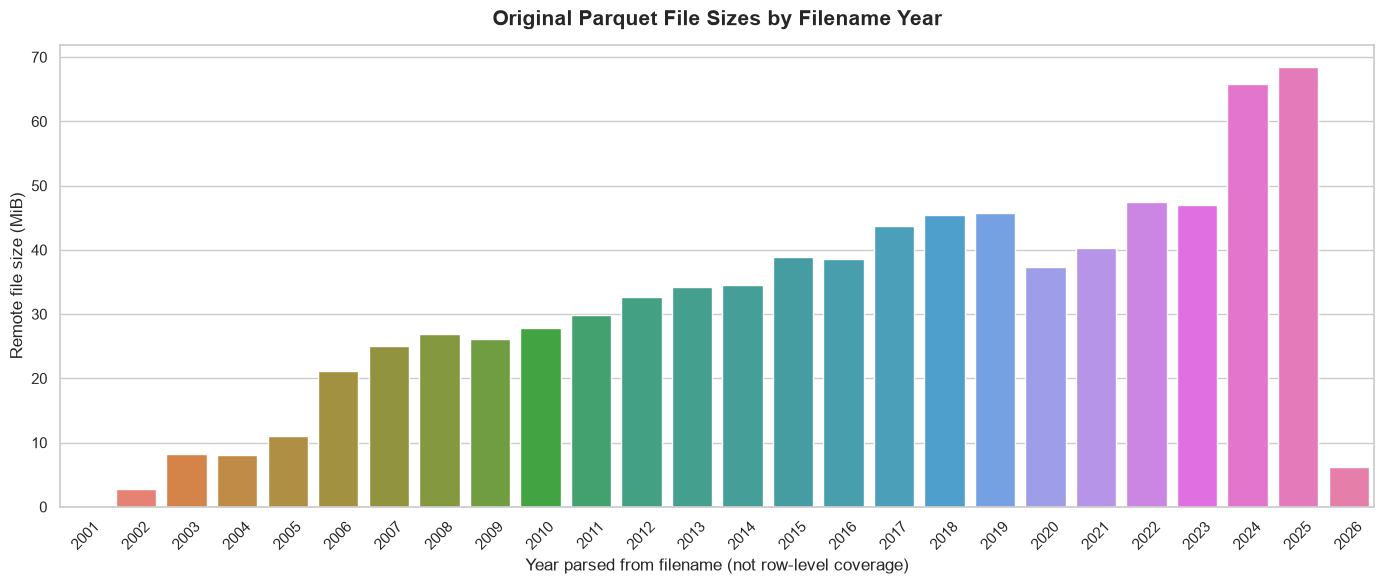

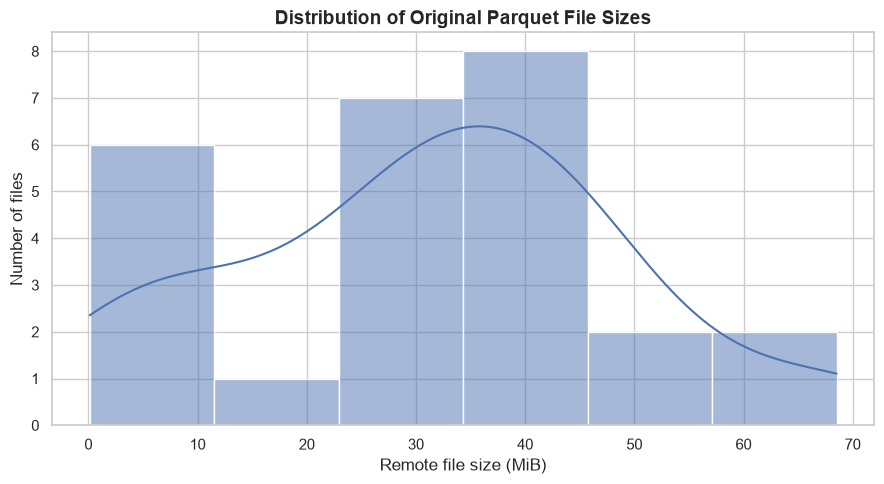

In [36]:
IMAGE_OUTPUT_DIR = PATHS.images_dir / "data_source_audit"
METADATA_OUTPUT_DIR = PATHS.artifacts_dir / "metadata"
PATHS.ensure_directories(IMAGE_OUTPUT_DIR, METADATA_OUTPUT_DIR)

sns.set_theme(context="notebook", style="whitegrid", palette="deep")

if not PARQUET_INVENTORY.empty and PARQUET_INVENTORY["size_mb"].notna().any():
    size_plot_data = PARQUET_INVENTORY.dropna(subset=["size_mb"]).copy()
    size_plot_data["display_label"] = size_plot_data.apply(
        lambda row: str(int(row["year_in_filename"])) if pd.notna(row["year_in_filename"]) else row["file_name"],
        axis=1,
    )
    size_plot_data = size_plot_data.sort_values(["year_in_filename", "file_name"], na_position="last")

    fig, ax = plt.subplots(figsize=(14, 6))
    sns.barplot(data=size_plot_data, x="display_label", y="size_mb", hue="display_label", legend=False, ax=ax)
    ax.set_title("Original Parquet File Sizes by Filename Year", fontsize=15, weight="bold", pad=14)
    ax.set_xlabel("Year parsed from filename (not row-level coverage)")
    ax.set_ylabel("Remote file size (MiB)")
    ax.tick_params(axis="x", rotation=45)
    fig.tight_layout()
    STATIC_SIZE_CHART_PATH = IMAGE_OUTPUT_DIR / "parquet_file_sizes_by_year.png"
    fig.savefig(STATIC_SIZE_CHART_PATH, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    if len(size_plot_data) >= 2:
        fig, ax = plt.subplots(figsize=(9, 5))
        sns.histplot(data=size_plot_data, x="size_mb", bins="auto", kde=len(size_plot_data) >= 5, ax=ax)
        ax.set_title("Distribution of Original Parquet File Sizes", fontsize=14, weight="bold")
        ax.set_xlabel("Remote file size (MiB)")
        ax.set_ylabel("Number of files")
        fig.tight_layout()
        STATIC_DISTRIBUTION_CHART_PATH = IMAGE_OUTPUT_DIR / "parquet_file_size_distribution.png"
        fig.savefig(STATIC_DISTRIBUTION_CHART_PATH, dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(fig)
else:
    print("Static file-size charts skipped: remote size metadata is unavailable.")

In [37]:
if not PARQUET_INVENTORY.empty:
    plot_data = PARQUET_INVENTORY.copy()
    plot_data["chart_label"] = plot_data.apply(
        lambda row: str(int(row["year_in_filename"])) if pd.notna(row["year_in_filename"]) else row["file_name"],
        axis=1,
    )
    plot_data = plot_data.dropna(subset=["size_mb"])

    if not plot_data.empty:
        interactive_size_figure = px.bar(
            plot_data.sort_values(["year_in_filename", "file_name"], na_position="last"),
            x="chart_label",
            y="size_mb",
            hover_data={"path": True, "size_mb": ":.3f", "chart_label": False},
            title="Remote Original Parquet Inventory — File Size by Filename Year",
            labels={"chart_label": "Filename year / file", "size_mb": "Remote size (MiB)"},
            template="plotly_white",
        )
        interactive_size_figure.update_layout(
            title_x=0.02,
            xaxis_tickangle=-45,
            margin=dict(l=45, r=25, t=75, b=95),
        )
        INTERACTIVE_SIZE_CHART_PATH = IMAGE_OUTPUT_DIR / "parquet_file_sizes_by_year.html"
        interactive_size_figure.write_html(INTERACTIVE_SIZE_CHART_PATH, include_plotlyjs=True)
        display(interactive_size_figure)
else:
    print("Interactive file-size chart skipped: no Parquet files were inventoried.")

## 19. Validate audit completeness and identify remaining unknowns

This is a source-discovery gate, not a data-quality gate. A source may pass repository discovery while still requiring local download verification, Parquet metadata inspection and a full data-quality audit.

In [38]:
REPOSITORY_ACCESS_OK = bool(RESOLVED_COMMIT and REMOTE_FILE_PATHS)
PARQUET_INVENTORY_OK = len(PARQUET_INVENTORY) > 0
SCHEMA_DISCOVERED = len(SCHEMA_INVENTORY) > 0
VIEWER_ROW_COUNT_AVAILABLE = VIEWER_ROW_COUNT is not None

AUDIT_GATE_ITEMS = [
    ("Repository metadata accessible", REPOSITORY_ACCESS_OK),
    ("Pinned immutable commit resolved", bool(RESOLVED_COMMIT)),
    ("Complete repository file listing retrieved", bool(REMOTE_FILE_PATHS)),
    ("Original Parquet inventory discovered", PARQUET_INVENTORY_OK),
    ("Dataset Viewer schema preview available", SCHEMA_DISCOVERED),
    ("Dataset Viewer row count available", VIEWER_ROW_COUNT_AVAILABLE),
]

AUDIT_GATE_DF = pd.DataFrame([
    {"gate": label, "status": "PASS" if passed else "REVIEW / UNAVAILABLE"}
    for label, passed in AUDIT_GATE_ITEMS
])
display(AUDIT_GATE_DF)

SOURCE_DISCOVERY_READY = all((REPOSITORY_ACCESS_OK, PARQUET_INVENTORY_OK, SCHEMA_DISCOVERED))
print("\nSOURCE DISCOVERY:", "READY FOR DOWNLOAD PLANNING" if SOURCE_DISCOVERY_READY else "INCOMPLETE — REVIEW THE FAILED GATES")

,gate,status
0,Repository metadata accessible,PASS
1,Pinned immutable commit resolved,PASS
2,Complete repository file listing retrieved,PASS
3,Original Parquet inventory discovered,PASS
4,Dataset Viewer schema preview available,PASS
5,Dataset Viewer row count available,PASS



SOURCE DISCOVERY: READY FOR DOWNLOAD PLANNING


## 20. Record limitations and hand-off requirements

Even when the source-discovery gates pass, the following checks remain mandatory in later notebooks/scripts:

1. Download every discovered original Parquet file using the pinned commit (or an explicitly reviewed newer commit).
2. Compare the local file inventory with this remote inventory.
3. Record each downloaded file's size and SHA-256 checksum; verify transfer integrity.
4. Inspect each Parquet footer and schema with PyArrow/Polars without reading all rows into Pandas.
5. Count rows from the actual Parquet files and reconcile the total with the remote Viewer and publisher-reported count.
6. Check for missing years, duplicate files, schema drift, nulls, invalid dates, impossible prices and duplicate observations.
7. Preserve the original downloaded files under `data/raw/`; never overwrite or delete source data during cleaning.
8. Confirm whether any observed fields actually represent quantity/arrivals before developing volume analysis. Price observations alone do not support arrivals forecasting.

### Known dataset-card caution

The public dataset card describes the source as market-price information and states that it does not provide arrivals quantity/volume. This audit still records the live published feature names rather than inventing or presuming a volume field. Any additional quantity field, if ever observed in a later revision, must be semantically validated before use.

## 21. Save audit artifacts

The report stores summaries and evidence references, not the raw response body or credential values. File inventories and schema metadata are stored as CSV for easy inspection. The five-row preview is not persisted by default to keep the audit artifact focused on metadata and provenance.

In [39]:
AUDIT_GENERATED_AT = datetime.now(timezone.utc).isoformat()

VIEWER_ENDPOINT_SUMMARY = {
    "is_valid": {
        "available": "is-valid" in VIEWER_RESULTS,
        "capabilities": VALIDITY_SUMMARY,
    },
    "splits": {
        "available": "splits" in VIEWER_RESULTS,
        "count": len(SPLIT_RECORDS),
        "items": SPLIT_RECORDS,
    },
    "size": {
        "available": "size" in VIEWER_RESULTS,
        **VIEWER_SIZE_SUMMARY,
    },
    "parquet": {
        "available": "parquet" in VIEWER_RESULTS,
        "file_count": len(VIEWER_PARQUET_FILES),
        "pending_count": len(VIEWER_PARQUET_PENDING),
        "failed_count": len(VIEWER_PARQUET_FAILED),
        "partial": VIEWER_PARQUET_RESPONSE.get("partial") if VIEWER_PARQUET_RESPONSE else None,
    },
    "first_rows": {
        "available": bool(FEATURES),
        "selected_split": SELECTED_SPLIT,
        "feature_count": len(FEATURES),
        "preview_rows_displayed": len(PREVIEW_DF),
        "error": FIRST_ROWS_ERROR,
    },
    "errors": VIEWER_ERRORS,
}

AUDIT_REPORT = {
    "report_name": "MandiLens India — Primary Data Source Audit",
    "report_version": "1.0.0",
    "generated_at_utc": AUDIT_GENERATED_AT,
    "audit_mode": "remote_metadata_only_no_bulk_download",
    "project": {
        "name": PROJECT_CONFIG.get("project", {}).get("name", "MandiLens India"),
        "version": PROJECT_CONFIG.get("project", {}).get("version"),
    },
    "source": {
        **SOURCE_CONTEXT,
        "repository_url": DATASET_URL,
        "requested_revision": REQUESTED_REVISION,
        "resolved_commit_sha": RESOLVED_COMMIT,
        "private": REPOSITORY_METADATA.get("private"),
        "gated": REPOSITORY_METADATA.get("gated"),
        "last_modified": REPOSITORY_METADATA.get("last_modified"),
    },
    "dataset_card": DATASET_CARD_SUMMARY,
    "repository_inventory": REPOSITORY_SUMMARY,
    "dataset_viewer": VIEWER_ENDPOINT_SUMMARY,
    "observed_schema": SCHEMA_RECORDS,
    "field_name_candidates": FIELD_CANDIDATES,
    "profile_comparison": PROFILE_COMPARISON,
    "inventory_checks": INVENTORY_CHECKS,
    "audit_gates": {label: bool(passed) for label, passed in AUDIT_GATE_ITEMS},
    "source_discovery_ready": bool(SOURCE_DISCOVERY_READY),
    "limitations": [
        "No bulk Parquet files were downloaded by this notebook.",
        "No full-row scan or local Parquet footer validation was performed.",
        "Dataset Viewer values are remote service metadata and may be refreshed or unavailable.",
        "File-name year tokens do not prove the actual minimum or maximum Arrival_Date values.",
        "Candidate field groups are name-based hints and require semantic validation.",
        "A successful source audit is not a data-quality certification.",
    ],
}

REPORT_PATH = METADATA_OUTPUT_DIR / "data_source_audit_report.json"
INVENTORY_CSV_PATH = METADATA_OUTPUT_DIR / "remote_source_file_inventory.csv"
SCHEMA_CSV_PATH = METADATA_OUTPUT_DIR / "remote_schema_inventory.csv"
VIEWER_PARQUET_CSV_PATH = METADATA_OUTPUT_DIR / "dataset_viewer_parquet_inventory.csv"

REPORT_PATH.write_text(
    json.dumps(AUDIT_REPORT, indent=2, ensure_ascii=False, default=str) + "\n",
    encoding="utf-8",
)
FILE_INVENTORY.to_csv(INVENTORY_CSV_PATH, index=False, encoding="utf-8")
SCHEMA_INVENTORY.to_csv(SCHEMA_CSV_PATH, index=False, encoding="utf-8")
pd.DataFrame(VIEWER_PARQUET_FILES).to_csv(VIEWER_PARQUET_CSV_PATH, index=False, encoding="utf-8")

print("Audit report and metadata inventories saved:")
for output_path in (REPORT_PATH, INVENTORY_CSV_PATH, SCHEMA_CSV_PATH, VIEWER_PARQUET_CSV_PATH):
    print(" -", PATHS.relative_path(output_path).as_posix())

Audit report and metadata inventories saved:
 - artifacts/metadata/data_source_audit_report.json
 - artifacts/metadata/remote_source_file_inventory.csv
 - artifacts/metadata/remote_schema_inventory.csv
 - artifacts/metadata/dataset_viewer_parquet_inventory.csv


## 22. Final source audit summary

The final status distinguishes repository discovery from the remaining acquisition and data-validation work. A `READY` source-discovery status is permission to plan the full download; it is not proof that local data has been acquired or validated.

In [40]:
FINAL_SUMMARY = {
    "repository_access": "PASS" if REPOSITORY_ACCESS_OK else "FAIL",
    "revision_pinned": "PASS" if RESOLVED_COMMIT else "FAIL",
    "repository_files": len(FILE_INVENTORY),
    "original_parquet_files": len(PARQUET_INVENTORY),
    "viewer_row_count": VIEWER_ROW_COUNT,
    "observed_schema_columns": len(SCHEMA_INVENTORY),
    "source_discovery_ready": SOURCE_DISCOVERY_READY,
    "bulk_download_performed": False,
    "full_dataset_row_validation_performed": False,
    "local_parquet_footer_validation_performed": False,
}

display(pd.DataFrame([FINAL_SUMMARY]).T.rename(columns={0: "result"}))

if SOURCE_DISCOVERY_READY:
    logger.info("MandiLens source audit completed; source discovery is ready for download planning.")
    print("\nSOURCE AUDIT COMPLETE — READY FOR THE FULL DATASET DOWNLOAD PLANNING STAGE")
else:
    logger.warning("MandiLens source audit completed with unresolved discovery gates.")
    print("\nSOURCE AUDIT COMPLETE — REVIEW UNAVAILABLE OR FAILED GATES BEFORE PROCEEDING")

print("No bulk data was downloaded. Raw source data was not modified.")
print("Next recommended step: implement the Hugging Face ingestion module and full-dataset download workflow.")

,result
repository_access,PASS
revision_pinned,PASS
repository_files,29
original_parquet_files,26
viewer_row_count,75962937
observed_schema_columns,11
source_discovery_ready,True
bulk_download_performed,False
full_dataset_row_validation_performed,False
local_parquet_footer_validation_performed,False


2026-11-15 12:54:20 | INFO | mandilens.notebooks.01_data_source_audit | MandiLens source audit completed; source discovery is ready for download planning.



SOURCE AUDIT COMPLETE — READY FOR THE FULL DATASET DOWNLOAD PLANNING STAGE
No bulk data was downloaded. Raw source data was not modified.
Next recommended step: implement the Hugging Face ingestion module and full-dataset download workflow.


## 23. Audit methodology and references

- Dataset repository: [Mandi India Daily Prices (2001–2026)](https://huggingface.co/datasets/DHIVAKARNAIDUSUNKARI/mandi-india-daily-prices-2001-2026)
- Hugging Face Hub API client: [HfApi reference](https://huggingface.co/docs/huggingface_hub/en/package_reference/hf_api)
- Dataset Viewer API: [Quickstart](https://huggingface.co/docs/dataset-viewer/quick_start)
- Dataset Viewer Parquet endpoint: [List Parquet files](https://huggingface.co/docs/dataset-viewer/parquet)
- Dataset Viewer size endpoint: [Get the number of rows and size](https://huggingface.co/docs/dataset-viewer/size)
- Dataset Viewer preview endpoint: [Download slices of rows](https://huggingface.co/docs/dataset-viewer/rows)

### Final hand-off

After executing the notebook from top to bottom, review `data_source_audit_report.json`, the remote Parquet inventory and the schema inventory. Confirm the source discovery result before proceeding to the next file in the roadmap. The next implementation must use the resolved commit SHA and the exact remote paths captured here rather than reconstructing a file list from year assumptions.